# Deep Learning Group Project: Tiny ImageNet

## Index

1. Exploratory Data Analysis (EDA)
2. Data preparation and image preprocessing
3. Train, validation, and test split
4. Model development (including a pre-trained transfer-learning approach)
5. Experimental setup, training, and intermediate experiments
6. Model evaluation and comparison
7. Error analysis
8. Conclusions and references / acknowledgements

# 1. Exploratory Data Analysis 



## 1.1 Load the labels and locate the images

The project data is expected in `Tiny_ImageNet_Project_2026_Students/`, next to this notebook. If your files are elsewhere, update `DATA_DIR` below.

In [12]:
from pathlib import Path
import pandas as pd

DATA_DIR_CANDIDATES = (
    Path("Tiny_ImageNet_Project_2026_Students"),
    Path("Deep-Learning") / "Tiny_ImageNet_Project_2026_Students",
)
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.is_dir()), DATA_DIR_CANDIDATES[0])
LABELS_PATH = DATA_DIR / "labels.csv"
IMAGES_DIR = DATA_DIR / "images"

for path in (LABELS_PATH, IMAGES_DIR):
    if not path.exists():
        raise FileNotFoundError(f"Expected project data at {path.resolve()}")

labels = pd.read_csv(LABELS_PATH)
image_paths = {path.name: path for path in IMAGES_DIR.iterdir() if path.is_file()}

print(f"Label rows: {len(labels):,}")
print(f"Image files: {len(image_paths):,}")
print(f"Label columns: {labels.columns.tolist()}")
display(labels.head())

Label rows: 60,000
Image files: 60,000
Label columns: ['filename', 'class_id', 'description']


,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


## 1.2 Check label-table quality

Check required columns, missing values, duplicate filenames, and whether each class ID maps to exactly one description.

In [13]:
required_columns = {"filename", "class_id", "description"}
missing_columns = required_columns - set(labels.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print("Missing values by column:")
display(labels[list(required_columns)].isna().sum().rename("missing_count").to_frame())
print(f"Duplicate filename rows: {labels['filename'].duplicated(keep=False).sum():,}")
class_description_counts = labels.groupby("class_id")["description"].nunique()
inconsistent_classes = class_description_counts[class_description_counts > 1]
print(f"Classes with multiple descriptions: {len(inconsistent_classes)}")
print(f"Unique classes: {labels['class_id'].nunique():,}")

Missing values by column:


,missing_count
filename,0
description,0
class_id,0


Duplicate filename rows: 0
Classes with multiple descriptions: 0
Unique classes: 200


## 1.3 Compare label references with files on disk

Do not silently discard missing files. Quantify both missing label references and image files without a label before deciding how to prepare the dataset.

In [14]:
label_filenames = set(labels["filename"].dropna().astype(str))
disk_filenames = set(image_paths)
missing_images = sorted(label_filenames - disk_filenames)
unlabeled_images = sorted(disk_filenames - label_filenames)

print(f"Label rows referencing files not found: {len(missing_images):,}")
print(f"Image files without a label row: {len(unlabeled_images):,}")
print("Examples of missing files:", missing_images[:10])
print("Examples of unlabeled files:", unlabeled_images[:10])

Label rows referencing files not found: 0
Image files without a label row: 0
Examples of missing files: []
Examples of unlabeled files: []


## 1.4 Inspect class balance

Report label counts per class, including labels whose image file is absent. The next cell also shows counts for files that are available.

In [15]:
class_counts = labels.groupby(["class_id", "description"], dropna=False).size().rename("label_rows")
available_labels = labels[labels["filename"].astype(str).isin(disk_filenames)]
unambiguous_labels = available_labels[~available_labels["filename"].duplicated(keep=False)]
available_class_counts = (
    unambiguous_labels.groupby(["class_id", "description"], dropna=False)
    .size()
    .rename("unambiguous_available_images")
)
class_summary = pd.concat([class_counts, available_class_counts], axis=1).fillna(0).astype(int)
display(class_summary.describe().T)
display(class_summary.sort_values("unambiguous_available_images").head(10))

,count,mean,std,min,25%,50%,75%,max
label_rows,200.0,300.0,152.723582,108.0,177.0,273.5,395.75,549.0
unambiguous_available_images,200.0,300.0,152.723582,108.0,177.0,273.5,395.75,549.0


,,label_rows,unambiguous_available_images
class_id,description,,
n07873807,"pizza, pizza pie",108,108
n07753592,banana,108,108
n02106662,"German shepherd, German shepherd dog, German police dog, alsatian",109,109
n01768244,trilobite,112,112
n03649909,"lawn mower, mower",113,113
n02977058,"cash machine, cash dispenser, automated teller machine, automatic teller machine, automated teller, automatic teller, ATM",114,114
n03930313,"picket fence, paling",114,114
n02410509,bison,114,114
n02666196,abacus,114,114


## 1.5 Review representative images

Visually inspect a small random sample before choosing image preprocessing. The sample is restricted to files with labels.

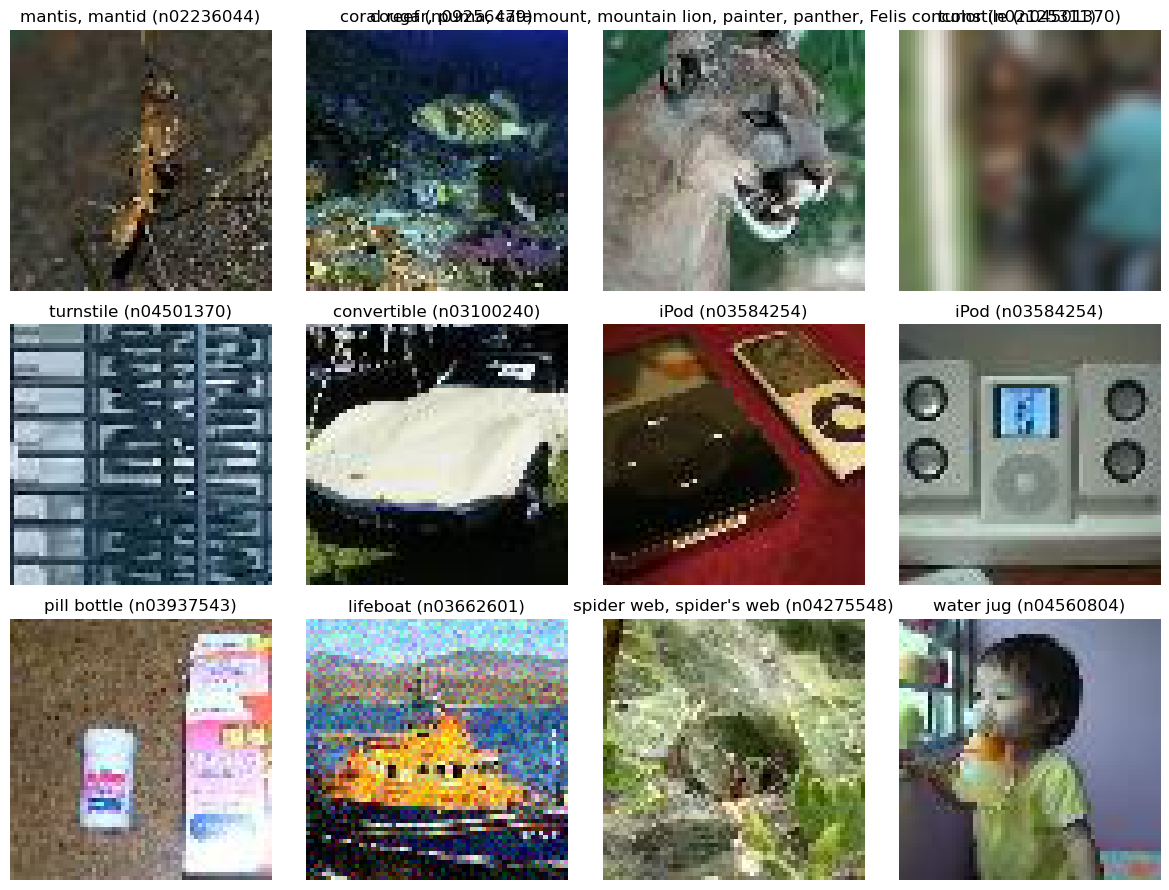

In [16]:
from PIL import Image

sample = unambiguous_labels.sample(n=min(12, len(unambiguous_labels)), random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    with Image.open(image_paths[str(row["filename"])]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row['description']} ({row['class_id']})")
    ax.axis("off")
for ax in axes.flat[len(sample):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 1.7 Initial observations and decisions

Record findings here after running the notebook:

- How many labeled rows refer to missing images?
- Are there duplicate filenames or inconsistent class descriptions?
- Is the class distribution balanced among available images?
- Do image dimensions, color modes, or visual quality vary?
- What data-cleaning and partitioning rules are justified by these findings?

Document any exclusions and split strategy before model training. In particular, make sure repeated or otherwise related images cannot leak across partitions.